In [1]:
import time
import random
import json
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import tensorflow as tf
import shutil
import seaborn as sns
from pathlib import Path
from tensorflow.keras import layers, models, regularizers, callbacks, optimizers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix,  roc_curve
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications import MobileNetV2


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1795842330.721876    1102 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.22.0-rc0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

def split_dataset(X, y, stratify=True):

    # Правильно разбивает датасет на train/val/test в пропорции 70/15/15

    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

In [3]:
dataset_path = Path("./PlantVillage")

subdirs = sorted([
    d for d in dataset_path.iterdir()
    if d.is_dir() and d.name != "PlantVillage"
])

print(f"Найдено папок классов: {len(subdirs)}")
for d in subdirs:
    print(f"  - {d.name}")

Найдено папок классов: 15
  - Pepper__bell___Bacterial_spot
  - Pepper__bell___healthy
  - Potato___Early_blight
  - Potato___Late_blight
  - Potato___healthy
  - Tomato_Bacterial_spot
  - Tomato_Early_blight
  - Tomato_Late_blight
  - Tomato_Leaf_Mold
  - Tomato_Septoria_leaf_spot
  - Tomato_Spider_mites_Two_spotted_spider_mite
  - Tomato__Target_Spot
  - Tomato__Tomato_YellowLeaf__Curl_Virus
  - Tomato__Tomato_mosaic_virus
  - Tomato_healthy


In [4]:
CLASS_NAMES = {0: "Tomato", 1: "Potato", 2: "Pepper"}
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def map_folder_to_class(folder_name: str):
    name_lower = folder_name.lower()
    if name_lower.startswith("tomato"):
        return 0, "Tomato"
    elif name_lower.startswith("potato"):
        return 1, "Potato"
    elif name_lower.startswith("pepper"):
        return 2, "Pepper"
    return None, None

records = []
corrupted_files = []

for folder in subdirs:
    class_id, class_name = map_folder_to_class(folder.name)
    if class_id is None:
        continue

    for file_path in folder.iterdir():
        if not file_path.is_file():
            continue
        if file_path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        # Проверка целостности изображения, формата, разрешения и MD5-хэша (для поиска точных дубликатов)
        try:
            with Image.open(file_path) as img:
                img.verify()  

            with Image.open(file_path) as img:
                width, height = img.size
                mode = img.mode
                img_format = img.format

            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            records.append({
                "filepath": str(file_path),
                "filename": file_path.name,
                "subfolder": folder.name,
                "class_id": class_id,
                "class_name": class_name,
                "width": width,
                "height": height,
                "mode": mode,
                "format": img_format,
                "md5": file_hash
            })
        except (UnidentifiedImageError, OSError, Exception) as e:
            corrupted_files.append((str(file_path), str(e)))

df = pd.DataFrame(records)

print("=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===")
print(f"Успешно проверено изображений: {len(df)}")
print(f"Повреждённых (битых) файлов: {len(corrupted_files)}")
if corrupted_files:
    print("Примеры битых файлов:", corrupted_files[:5])

print("Уникальные размеры изображений (W x H):")
print(df.groupby(["width", "height"]).size())


n_dups = df["md5"].duplicated().sum()
print(f"\nНайдено точных дубликатов файлов (MD5): {n_dups}")

=== ОТЧЁТ О ПРОВЕРКЕ ДАННЫХ ===
Успешно проверено изображений: 20638
Повреждённых (битых) файлов: 0
Уникальные размеры изображений (W x H):
width  height
256    256       20638
dtype: int64

Найдено точных дубликатов файлов (MD5): 14


In [5]:
print("\n=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===")
class_counts = df.groupby(["class_id", "class_name"]).size().reset_index(name="count")
class_counts["percent"] = (class_counts["count"] / len(df) * 100).round(2)
print(class_counts.to_string(index=False))

print("\n=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===")
sub_counts = df.groupby(["class_name", "subfolder"]).size().reset_index(name="count")
print(sub_counts.to_string(index=False))


=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===
 class_id class_name  count  percent
        0     Tomato  16011    77.58
        1     Potato   2152    10.43
        2     Pepper   2475    11.99

=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===
class_name                                   subfolder  count
    Pepper               Pepper__bell___Bacterial_spot    997
    Pepper                      Pepper__bell___healthy   1478
    Potato                       Potato___Early_blight   1000
    Potato                        Potato___Late_blight   1000
    Potato                            Potato___healthy    152
    Tomato                       Tomato_Bacterial_spot   2127
    Tomato                         Tomato_Early_blight   1000
    Tomato                          Tomato_Late_blight   1909
    Tomato                            Tomato_Leaf_Mold    952
    Tomato                   Tomato_Septoria_leaf_spot   1771
    Tomato Tomato_Spider_mites_Two_spotted_spider_mite   1676
    

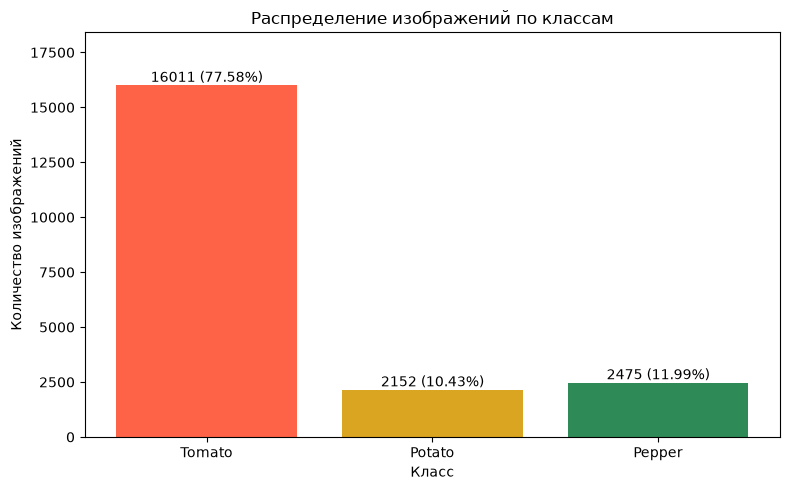

In [6]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts["class_name"],
    class_counts["count"],
    color=["tomato", "goldenrod", "seagreen"]
)

for bar, count, percent in zip(
    bars,
    class_counts["count"],
    class_counts["percent"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} ({percent:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.title("Распределение изображений по классам")
plt.xlabel("Класс")
plt.ylabel("Количество изображений")
plt.ylim(0, class_counts["count"].max() * 1.15)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

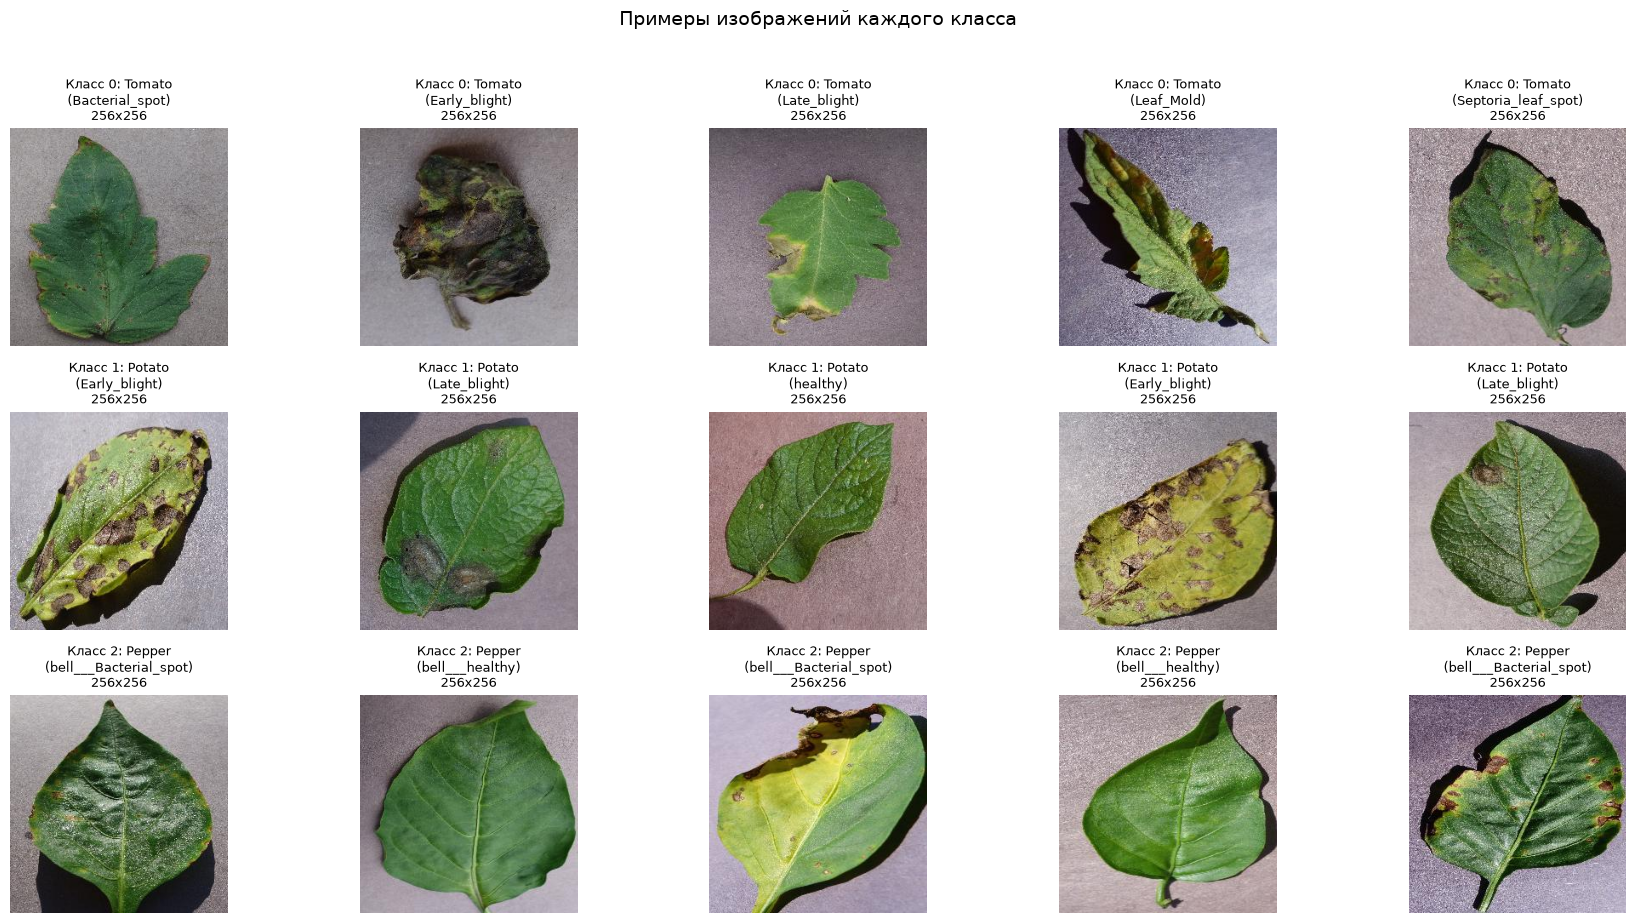

In [7]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(18, 9))

for row_idx, (class_id, class_name) in enumerate(CLASS_NAMES.items()):
    class_df = df[df["class_id"] == class_id]
    
    # Выбираем примеры из разных подклассов, если их несколько
    unique_subs = class_df["subfolder"].unique()
    sampled_rows = []
    for i in range(5):
        sub = unique_subs[i % len(unique_subs)]
        sample = class_df[class_df["subfolder"] == sub].sample(1, random_state=SEED + i)
        sampled_rows.append(sample.iloc[0])
    
    for col_idx, row in enumerate(sampled_rows):
        ax = axes[row_idx, col_idx]
        with Image.open(row["filepath"]) as img:
            ax.imshow(img)
        
        sub_short = row["subfolder"].replace(f"{class_name}___", "").replace(f"{class_name}__", "").replace(f"{class_name}_", "")
        ax.set_title(
            f"Класс {class_id}: {class_name}\n({sub_short})\n{row['width']}x{row['height']}",
            fontsize=9
        )
        ax.axis("off")

plt.suptitle("Примеры изображений каждого класса", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
ARTIFACTS_DIR = Path("./artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

splits_path = ARTIFACTS_DIR / "dataset_splits_var0.csv"

# Загружаем разбиение из первой части лабораторной
splits_df = pd.read_csv(splits_path)

train_df = splits_df[
    splits_df["split"] == "train"
].reset_index(drop=True)

val_df = splits_df[
    splits_df["split"] == "val"
].reset_index(drop=True)

test_df = splits_df[
    splits_df["split"] == "test"
].reset_index(drop=True)

df_clean = splits_df.copy()

print("Загружено разбиение из первой части")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Удалено точных дубликатов (MD5): 14. Осталось уникальных изображений: 20624
Проверка на утечку данных пройдена: пересечений по путям и MD5 нет.
Разбиение сохранено в: artifacts/dataset_splits_var0.csv


In [9]:
total = len(df_clean)
print("\n=== РАЗМЕРЫ ВЫБОРОК ===")
for name, part in [("Train (70%)", train_df), ("Val (15%)", val_df), ("Test (15%)", test_df)]:
    print(f"{name:<12}: {len(part):>6} изображений ({len(part) / total * 100:.2f}%)")

print("\n=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===")
summary = pd.DataFrame({
    "Train_cnt": train_df["class_name"].value_counts(),
    "Train_%": (train_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Val_cnt": val_df["class_name"].value_counts(),
    "Val_%": (val_df["class_name"].value_counts(normalize=True) * 100).round(2),
    "Test_cnt": test_df["class_name"].value_counts(),
    "Test_%": (test_df["class_name"].value_counts(normalize=True) * 100).round(2),
})
print(summary)

# Для трёхклассовой классификации (0: Tomato, 1: Potato, 2: Pepper)
multi_classes = np.array([0, 1, 2])
multi_weights = compute_class_weight(
    class_weight="balanced",
    classes=multi_classes,
    y=train_df["class_id"].values
)
CLASS_WEIGHTS_MULTI = dict(zip(multi_classes, multi_weights))

print("Веса классов для 3-классовой модели (по train):", {k: round(float(v), 4) for k, v in CLASS_WEIGHTS_MULTI.items()})


=== РАЗМЕРЫ ВЫБОРОК ===
Train (70%) :  14436 изображений (70.00%)
Val (15%)   :   3094 изображений (15.00%)
Test (15%)  :   3094 изображений (15.00%)

=== РАСПРЕДЕЛЕНИЕ КЛАССОВ (МНОГОКЛАССОВАЯ ЗАДАЧА: 0, 1, 2) ===
            Train_cnt  Train_%  Val_cnt  Val_%  Test_cnt  Test_%
class_name                                                      
Tomato          11197    77.56     2400  77.57      2400   77.57
Pepper           1733    12.00      371  11.99       371   11.99
Potato           1506    10.43      323  10.44       323   10.44
Веса классов для 3-классовой модели (по train): {np.int64(0): 0.4298, np.int64(1): 3.1952, np.int64(2): 2.7767}


In [ ]:
from itertools import combinations

parts = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

check_columns = ["filepath", "md5"]

if "group_id" in splits_df.columns:
    check_columns.append("group_id")

for (name_a, a), (name_b, b) in combinations(
    parts.items(), 2
):
    for col in check_columns:

        overlap = set(a[col]) & set(b[col])

        print(
            f"{name_a} / {name_b} | "
            f"{col}: {len(overlap)} пересечений"
        )

        assert not overlap, (
            f"Утечка данных: {name_a} / {name_b}, {col}"
        )

    if "phash" in splits_df.columns:
        common_phash = set(a["phash"]) & set(b["phash"])

        print("Совпадений pHash:", len(common_phash))

print("Проверки завершены.")

In [10]:
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU активирован с memory_growth: {gpus}")
    except RuntimeError as e:
        print(f"GPU уже инициализирован, memory_growth не изменён: {e}")

IMG_SIZE = (224, 224)
BATCH_SIZE = 64  
AUTOTUNE = tf.data.AUTOTUNE

def create_tf_dataset(dataframe: pd.DataFrame, img_size: tuple = IMG_SIZE, batch_size: int = BATCH_SIZE, shuffle: bool = False, cache: bool = False, preprocess_fn=None, seed: int = SEED) -> tf.data.Dataset:

    filepaths = dataframe["filepath"].values
    labels = dataframe["class_id"].values.astype(np.int32)

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    def load_and_preprocess(path, label):
        img_bytes = tf.io.read_file(path)
        img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
        img = tf.image.resize(img, img_size, method=tf.image.ResizeMethod.BILINEAR)
        img = tf.cast(img, tf.float32)

        if preprocess_fn is not None:
            img = preprocess_fn(img)
        else:
            img = img / 255.0  # [0; 1] для собственной CNN

        img.set_shape([img_size[0], img_size[1], 3])
        return img, label

    # Декодирование и ресайз распараллеливаются по ядрам CPU
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)

    if cache:
        ds = ds.cache()  # Храним готовые тензоры в ОЗУ (~8.5 ГБ для train)

    if shuffle:
        # reshuffle_each_iteration=True заново перемешивает кэш на каждой эпохе
        ds = ds.shuffle(buffer_size=len(dataframe), seed=seed, reshuffle_each_iteration=True)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds

GPU активирован с memory_growth: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Создаём 3-классовые выборки (0: Tomato, 1: Potato, 2: Pepper) со строгой MobileNetV2-предобработкой
train_ds_multi = create_tf_dataset(
    train_df, shuffle=True, cache=True, preprocess_fn=mobilenet_preprocess
)
val_ds_multi = create_tf_dataset(
    val_df, shuffle=False, cache=True, preprocess_fn=mobilenet_preprocess
)
test_ds_multi = create_tf_dataset(
    test_df, shuffle=False, cache=False, preprocess_fn=mobilenet_preprocess
)

# Быстрая проверка диапазона пикселей (для MobileNetV2 должно быть примерно [-1.0, 1.0]) и меток {0, 1, 2}
xb, yb = next(iter(train_ds_multi))
print(f"Форма батча: {xb.shape}, диапазон пикселей: [{xb.numpy().min():.2f}, {xb.numpy().max():.2f}]")
print("Уникальные метки в батче:", np.unique(yb.numpy()))
print(f"Размеры выборок -> train: {len(train_df)}, val: {len(val_df)}, test: {len(test_df)}")



I0000 00:00:1795842345.334522    1102 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5561 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060, pci bus id: 0000:05:00.0, compute capability: 8.9


Форма батча: (64, 224, 224, 3), диапазон пикселей: [-1.00, 0.99]
Уникальные метки в батче: [0 1 2]
Размеры выборок -> train: 14436, val: 3094, test: 3094


Режим A | Всего параметров: 2,261,827 | Обучаемых: 3,843
Epoch 1/15


/home/valery/code/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795842352.811141    1102 service.cc:154] XLA service 0x45e172e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795842352.811182    1102 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 4060, Compute Capability 8.9 (Driver: 13.4.0[617.14.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1795842352.856053    1102 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795842353.389480    1102 cuda_dnn.cc:442] Loaded cuDNN version 92600
W0000 00:00:1795842355.136090    1431 cuda_timer.cc:88] Delay ke

  3/226 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.3698 - loss: 0.9670  

I0000 00:00:1795842360.809930    1102 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 13/226 ━━━━━━━━━━━━━━━━━━━━ 8s 42ms/step - accuracy: 0.6442 - loss: 0.8181

W0000 00:00:1795842361.270502    1411 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1795842351124302588 in buffer 'PrefetchDataset/_17' sat unconsumed for 10.1392 seconds!


... (3 outputs left out)

W0000 00:00:1795842383.334611    2979 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
W0000 00:00:1795842386.243812    2981 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.



Epoch 1: val_loss improved from None to 0.10412, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 1: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 37s 122ms/step - accuracy: 0.9334 - loss: 0.1887 - val_accuracy: 0.9706 - val_loss: 0.1041 - learning_rate: 0.0010
Epoch 2/15
  1/226 ━━━━━━━━━━━━━━━━━━━━ 14:07 4s/step - accuracy: 0.9688 - loss: 0.1095

W0000 00:00:1795842392.001570    1102 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9796 - loss: 0.0630
Epoch 2: val_loss improved from 0.10412 to 0.07256, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 2: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 17s 59ms/step - accuracy: 0.9796 - loss: 0.0630 - val_accuracy: 0.9758 - val_loss: 0.0726 - learning_rate: 0.0010
Epoch 3/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.9851 - loss: 0.0449
Epoch 3: val_loss improved from 0.07256 to 0.06141, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoch 3: finished saving model to artifacts/TL_ModeA_Frozen_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - accuracy: 0.9851 - loss: 0.0449 - val_accuracy: 0.9800 - val_loss: 0.0614 - learning_rate: 0.0010
Epoch 4/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9863 - loss: 0.0363
Epoch 4: val_loss improved from 0.06141 to 0.04906, saving model to artifacts/TL_ModeA_Frozen_best.keras

Epoc

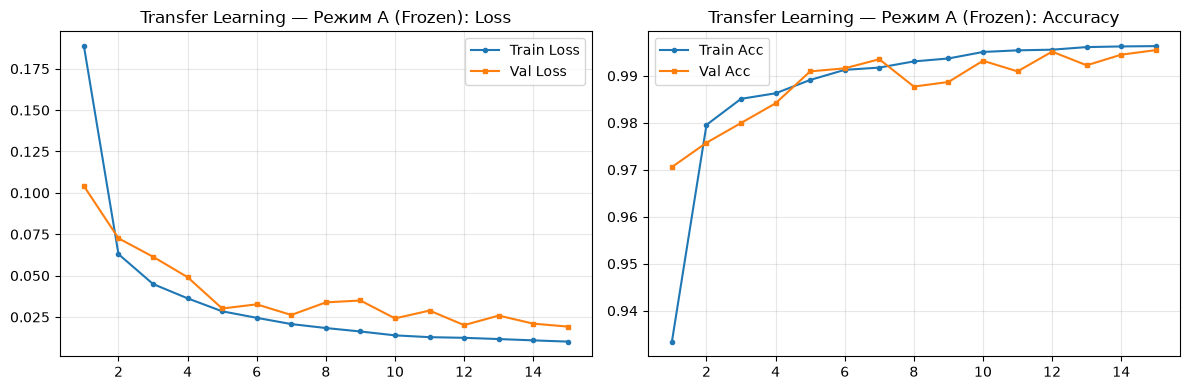

In [12]:
tf.keras.utils.set_random_seed(SEED)
INPUT_SHAPE = (224, 224, 3)
ARTIFACTS_DIR = Path("./artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)


# 1. Загружаем предобученный backbone без верхней классификационной части
base_model = MobileNetV2(
    input_shape=INPUT_SHAPE,
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Замораживаем все слои основы

# 2. Собираем модель с помощью Functional API
inputs = layers.Input(shape=INPUT_SHAPE)
x = base_model(inputs, training=False)  # training=False важно для заморозки статистик BN внутри основы
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="head_dropout")(x)
outputs = layers.Dense(3, activation="softmax", name="head_output")(x)

model_tl_frozen = models.Model(inputs, outputs, name="MobileNetV2_ModeA_Frozen")

model_tl_frozen.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params_A = np.sum([np.prod(w.shape) for w in model_tl_frozen.trainable_weights])
print(f"Режим A | Всего параметров: {model_tl_frozen.count_params():,} | Обучаемых: {trainable_params_A:,}")

ckpt_A = ARTIFACTS_DIR / "TL_ModeA_Frozen_best.keras"
cb_A = [
    callbacks.ModelCheckpoint(str(ckpt_A), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

t0 = time.perf_counter()
hist_A = model_tl_frozen.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=15,
    class_weight=CLASS_WEIGHTS_MULTI,
    callbacks=cb_A,
    verbose=1
)
time_A = time.perf_counter() - t0

hist_A_dict = {k: [float(v) for v in vals] for k, vals in hist_A.history.items()}
with open(ARTIFACTS_DIR / "TL_ModeA_history.json", "w", encoding="utf-8") as f:
    json.dump(hist_A_dict, f, indent=2)

# Отдельные графики Loss и Accuracy для Режима A (требование Этапа 6)
ep_A = range(1, len(hist_A_dict["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep_A, hist_A_dict["loss"], label="Train Loss", marker="o", markersize=3)
axes[0].plot(ep_A, hist_A_dict["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[0].set_title("Transfer Learning — Режим A (Frozen): Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_A, hist_A_dict["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[1].plot(ep_A, hist_A_dict["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[1].set_title("Transfer Learning — Режим A (Frozen): Accuracy"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage5_modeA_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Режим B | Разморожено слоёв основы: 30 (без BN) | Обучаемых параметров: 1,514,563
Epoch 1/15
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9887 - loss: 0.0234
Epoch 1: val_loss improved from None to 0.03512, saving model to artifacts/TL_ModeB_FineTuned_best.keras

Epoch 1: finished saving model to artifacts/TL_ModeB_FineTuned_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 26s 89ms/step - accuracy: 0.9887 - loss: 0.0234 - val_accuracy: 0.9874 - val_loss: 0.0351 - learning_rate: 3.0000e-05
Epoch 2/15
  1/226 ━━━━━━━━━━━━━━━━━━━━ 23s 105ms/step - accuracy: 1.0000 - loss: 0.0101

W0000 00:00:1795842598.305844    1102 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 38535680 bytes after encountering the first element of size 38535680 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9948 - loss: 0.0112
Epoch 2: val_loss improved from 0.03512 to 0.00844, saving model to artifacts/TL_ModeB_FineTuned_best.keras

Epoch 2: finished saving model to artifacts/TL_ModeB_FineTuned_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.9948 - loss: 0.0112 - val_accuracy: 0.9987 - val_loss: 0.0084 - learning_rate: 3.0000e-05
Epoch 3/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9967 - loss: 0.0076
Epoch 3: val_loss improved from 0.00844 to 0.00801, saving model to artifacts/TL_ModeB_FineTuned_best.keras

Epoch 3: finished saving model to artifacts/TL_ModeB_FineTuned_best.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.9967 - loss: 0.0076 - val_accuracy: 0.9984 - val_loss: 0.0080 - learning_rate: 3.0000e-05
Epoch 4/15
225/226 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.9997 - loss: 9.2288e-04
Epoch 4: val_loss improved from 0.00801 to 0.00755, saving model to artifacts/TL_ModeB

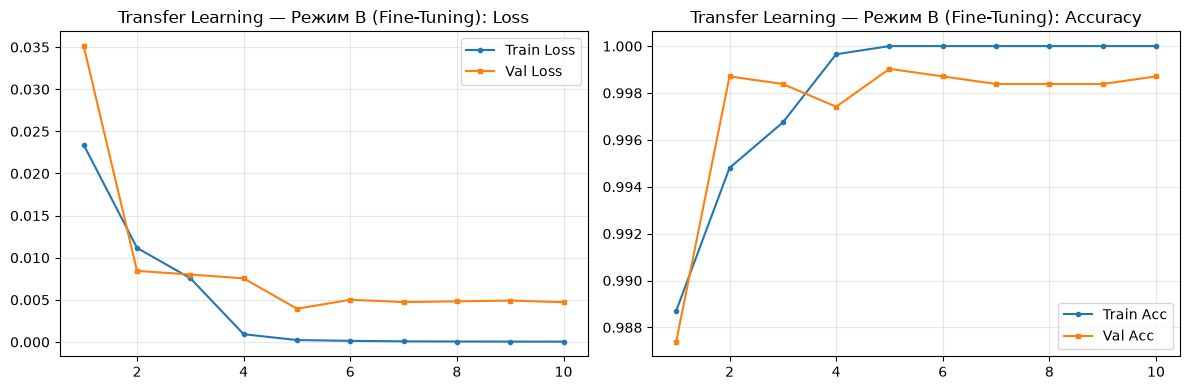

In [13]:
# 1. Загружаем лучшую модель Режима A, чтобы адаптировать её дальше
model_tl_ft = models.load_model(ckpt_A)

# Находим вложенный backbone MobileNetV2
backbone_layer = [l for l in model_tl_ft.layers if isinstance(l, tf.keras.Model)][0]
backbone_layer.trainable = True

# Замораживаем все слои, кроме последних 30, а также держим замороженными все BatchNorm
FINE_TUNE_AT = len(backbone_layer.layers) - 30
for i, layer in enumerate(backbone_layer.layers):
    if i < FINE_TUNE_AT or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# 2. Обязательная повторная компиляция после изменения trainable с малой скоростью обучения
model_tl_ft.compile(
    optimizer=optimizers.Adam(learning_rate=3e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_params_B = np.sum([np.prod(w.shape) for w in model_tl_ft.trainable_weights])
print(f"Режим B | Разморожено слоёв основы: 30 (без BN) | Обучаемых параметров: {trainable_params_B:,}")

ckpt_B = ARTIFACTS_DIR / "TL_ModeB_FineTuned_best.keras"
cb_B = [
    callbacks.ModelCheckpoint(str(ckpt_B), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=5, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

t0 = time.perf_counter()
hist_B = model_tl_ft.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=15,
    class_weight=CLASS_WEIGHTS_MULTI,
    callbacks=cb_B,
    verbose=1
)
time_B = time.perf_counter() - t0

hist_B_dict = {k: [float(v) for v in vals] for k, vals in hist_B.history.items()}
with open(ARTIFACTS_DIR / "TL_ModeB_history.json", "w", encoding="utf-8") as f:
    json.dump(hist_B_dict, f, indent=2)

# Отдельные графики Loss и Accuracy для Режима B (требование Этапа 6)
ep_B = range(1, len(hist_B_dict["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep_B, hist_B_dict["loss"], label="Train Loss", marker="o", markersize=3)
axes[0].plot(ep_B, hist_B_dict["val_loss"], label="Val Loss", marker="s", markersize=3)
axes[0].set_title("Transfer Learning — Режим B (Fine-Tuning): Loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_B, hist_B_dict["accuracy"], label="Train Acc", marker="o", markersize=3)
axes[1].plot(ep_B, hist_B_dict["val_accuracy"], label="Val Acc", marker="s", markersize=3)
axes[1].set_title("Transfer Learning — Режим B (Fine-Tuning): Accuracy"); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage5_modeB_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
print("\n=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===")
class_counts = df.groupby(["class_id", "class_name"]).size().reset_index(name="count")
class_counts["percent"] = (class_counts["count"] / len(df) * 100).round(2)
print(class_counts.to_string(index=False))

print("\n=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===")
sub_counts = df.groupby(["class_name", "subfolder"]).size().reset_index(name="count")
print(sub_counts.to_string(index=False))


=== КОЛИЧЕСТВО ИЗОБРАЖЕНИЙ ПО ОСНОВНЫМ КЛАССАМ ===
 class_id class_name  count  percent
        0     Tomato  16011    77.58
        1     Potato   2152    10.43
        2     Pepper   2475    11.99

=== РАЗБИВКА ПО ПОДПАПКАМ (БОЛЕЗНИ / ЗДОРОВЫЕ) ===
class_name                                   subfolder  count
    Pepper               Pepper__bell___Bacterial_spot    997
    Pepper                      Pepper__bell___healthy   1478
    Potato                       Potato___Early_blight   1000
    Potato                        Potato___Late_blight   1000
    Potato                            Potato___healthy    152
    Tomato                       Tomato_Bacterial_spot   2127
    Tomato                         Tomato_Early_blight   1000
    Tomato                          Tomato_Late_blight   1909
    Tomato                            Tomato_Leaf_Mold    952
    Tomato                   Tomato_Septoria_leaf_spot   1771
    Tomato Tomato_Spider_mites_Two_spotted_spider_mite   1676
    

=== СРАВНЕНИЕ РЕЖИМОВ TRANSFER LEARNING НА ВАЛИДАЦИИ ===
                    Режим      LR  Эпох  Время, с   Loss  Accuracy  Macro Precision  Macro Recall  Macro F1
   A: Замороженная основа 0.00100    15     219.5 0.0192    0.9955           0.9889        0.9945    0.9917
B: Fine-tuning (30 слоёв) 0.00003    10     142.3 0.0039    0.9990           0.9971        0.9996    0.9983

Лучший режим по валидации: B: Fine-tuning (30 слоёв) -> сохранено в artifacts/best_multiclass_tl.keras


W0000 00:00:1795842745.392299    1102 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
W0000 00:00:1795842751.743680    1102 prefetch_autotuner.cc:56] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size



=== ИТОГОВЫЕ МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ (3 КЛАССА) ===
                    Режим   Loss  Accuracy  Macro Precision  Macro Recall  Macro F1
   A: Замороженная основа 0.0297    0.9900           0.9780        0.9854    0.9816
B: Fine-tuning (30 слоёв) 0.0142    0.9952           0.9919        0.9909    0.9914

--- Подробный отчёт по классам на TEST: Режим A (Frozen) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9958    0.9921    0.9939      2400
  Potato (1)     0.9515    0.9721    0.9617       323
  Pepper (2)     0.9866    0.9919    0.9892       371

    accuracy                         0.9900      3094
   macro avg     0.9780    0.9854    0.9816      3094
weighted avg     0.9901    0.9900    0.9900      3094

--- Подробный отчёт по классам на TEST: Режим B (Fine-Tuning) ---
              precision    recall  f1-score   support

  Tomato (0)     0.9967    0.9971    0.9969      2400
  Potato (1)     0.9844    0.9783    0.9814       323
  Pepper (2)     0.

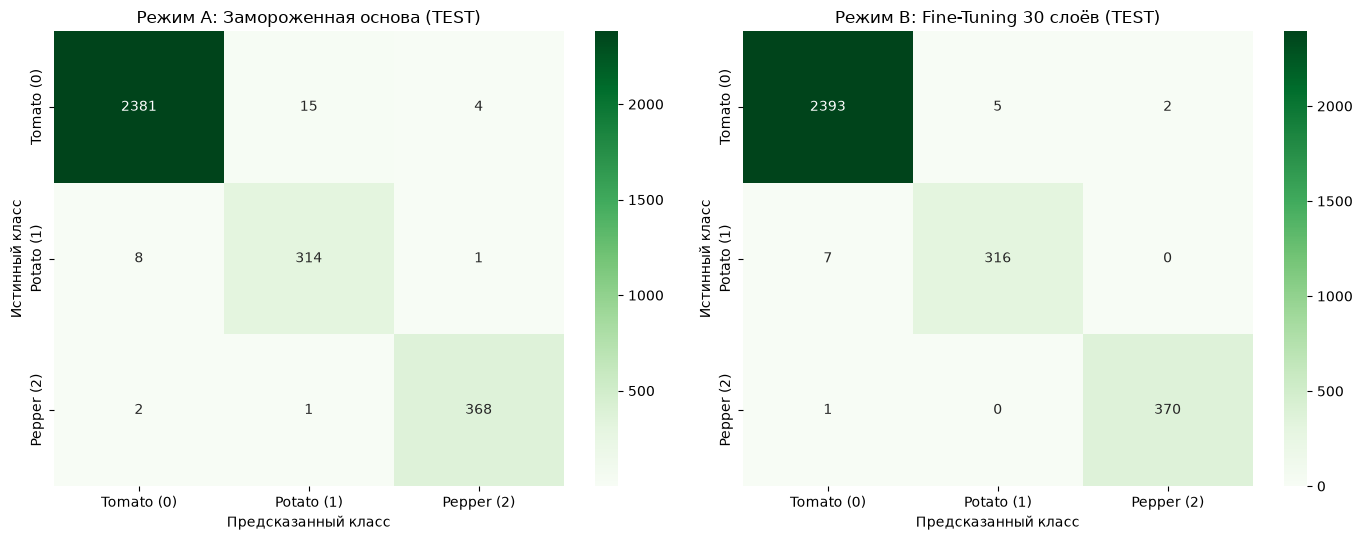

In [15]:
CLASS_LABELS = ["Tomato (0)", "Potato (1)", "Pepper (2)"]
y_val_multi_true = np.concatenate([y.numpy() for _, y in val_ds_multi], axis=0)
y_test_multi_true = np.concatenate([y.numpy() for _, y in test_ds_multi], axis=0)

def evaluate_multiclass(ckpt_path, ds, y_true):
    m = models.load_model(ckpt_path)
    loss = m.evaluate(ds, verbose=0)[0]
    y_prob = m.predict(ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    metrics_dict = {
        "Loss": round(float(loss), 4),
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro Precision": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
    }
    return metrics_dict, y_pred

# 1. Сравнение на ВАЛИДАЦИИ и выбор лучшей 3-классовой модели
val_A, _ = evaluate_multiclass(ckpt_A, val_ds_multi, y_val_multi_true)
val_B, _ = evaluate_multiclass(ckpt_B, val_ds_multi, y_val_multi_true)

val_tl_df = pd.DataFrame([
    {"Режим": "A: Замороженная основа", "LR": 1e-3, "Эпох": len(hist_A_dict["loss"]), "Время, с": round(time_A, 1), **val_A},
    {"Режим": "B: Fine-tuning (30 слоёв)", "LR": 3e-5, "Эпох": len(hist_B_dict["loss"]), "Время, с": round(time_B, 1), **val_B},
])
print("=== СРАВНЕНИЕ РЕЖИМОВ TRANSFER LEARNING НА ВАЛИДАЦИИ ===")
print(val_tl_df.to_string(index=False))

best_tl_idx = val_tl_df["Macro F1"].idxmax()
best_ckpt_src = ckpt_A if best_tl_idx == 0 else ckpt_B
shutil.copyfile(best_ckpt_src, ARTIFACTS_DIR / "best_multiclass_tl.keras")
print(f"\nЛучший режим по валидации: {val_tl_df.loc[best_tl_idx, 'Режим']} -> сохранено в artifacts/best_multiclass_tl.keras")

# 2. Итоговая оценка обоих режимов на ОТЛОЖЕННОЙ ТЕСТОВОЙ ВЫБОРКЕ
test_A, y_pred_test_A = evaluate_multiclass(ckpt_A, test_ds_multi, y_test_multi_true)
test_B, y_pred_test_B = evaluate_multiclass(ckpt_B, test_ds_multi, y_test_multi_true)

test_tl_df = pd.DataFrame([
    {"Режим": "A: Замороженная основа", **test_A},
    {"Режим": "B: Fine-tuning (30 слоёв)", **test_B},
])
test_tl_df.to_csv(ARTIFACTS_DIR / "stage5_6_multiclass_test_comparison.csv", index=False)

print("\n=== ИТОГОВЫЕ МЕТРИКИ НА ТЕСТОВОЙ ВЫБОРКЕ (3 КЛАССА) ===")
print(test_tl_df.to_string(index=False))

print("\n--- Подробный отчёт по классам на TEST: Режим A (Frozen) ---")
print(classification_report(y_test_multi_true, y_pred_test_A, target_names=CLASS_LABELS, digits=4))

print("--- Подробный отчёт по классам на TEST: Режим B (Fine-Tuning) ---")
print(classification_report(y_test_multi_true, y_pred_test_B, target_names=CLASS_LABELS, digits=4))

# 3. Матрицы ошибок на TEST для обоих режимов
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, y_p, title in [
    (axes[0], y_pred_test_A, "Режим A: Замороженная основа (TEST)"),
    (axes[1], y_pred_test_B, "Режим B: Fine-Tuning 30 слоёв (TEST)")
]:
    cm = confusion_matrix(y_test_multi_true, y_p)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens",
        xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Истинный класс")

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "stage6_multiclass_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show() 

## Вывод по многоклассовой классификации

В ходе выполнения второй части лабораторной работы
была решена задача многоклассовой классификации
изображений растений с использованием предварительно
обученной на ImageNet нейронной сети MobileNetV2.

Для классификации использовались три класса:

- Tomato — класс 0;
- Potato — класс 1;
- Pepper — класс 2.

Изображения были приведены к размеру 224 × 224 пикселя
и трёхканальному RGB-формату.

Для предварительной обработки использовалась функция
preprocess_input архитектуры MobileNetV2, преобразующая
значения пикселей в диапазон [-1; 1].

### Исследование режимов Transfer Learning

Были реализованы два режима переноса обучения.

**Режим A — Frozen backbone.**

Свёрточная основа MobileNetV2 была полностью
заморожена. Обучение выполнялось исключительно
для новой классификационной головы, состоящей
из GlobalAveragePooling2D, Dropout и выходного
слоя Dense с функцией активации Softmax.

В качестве оптимизатора использовался Adam
с начальной скоростью обучения 0.001.

**Режим B — Fine-tuning.**

Для тонкой настройки использовалась лучшая модель,
полученная в режиме A.

Верхняя часть свёрточной основы была частично
разморожена, при этом слои BatchNormalization
оставались замороженными.

После изменения параметра trainable модель была
повторно скомпилирована с использованием Adam
и уменьшенной скоростью обучения 0.00003.

Уменьшение скорости обучения позволило выполнять
адаптацию предварительно обученных признаков
без их резкого изменения.

### Сравнение результатов на валидационной выборке

| Метрика | Frozen | Fine-tuning |
|---|---:|---:|
| Loss | 0.0192 | 0.0039 |
| Accuracy | 0.9955 | 0.9990 |
| Macro Precision | 0.9889 | 0.9971 |
| Macro Recall | 0.9945 | 0.9996 |
| Macro F1 | 0.9917 | 0.9983 |
| Количество эпох | 15 | 10 |
| Время обучения, с | 219.5 | 142.3 |

По результатам валидационной выборки лучшей моделью
была выбрана MobileNetV2 в режиме Fine-tuning.

Значение Macro-F1 увеличилось с 0.9917 до 0.9983,
а значение функции потерь уменьшилось
с 0.0192 до 0.0039.

### Сравнение результатов на тестовой выборке

| Метрика | Frozen | Fine-tuning |
|---|---:|---:|
| Loss | 0.0297 | 0.0142 |
| Accuracy | 0.9900 | 0.9952 |
| Macro Precision | 0.9780 | 0.9919 |
| Macro Recall | 0.9854 | 0.9909 |
| Macro F1 | 0.9816 | 0.9914 |

Применение Fine-tuning позволило увеличить Accuracy
на 0.52 процентного пункта, а Macro-F1 —
на 0.98 процентного пункта.

Также наблюдается снижение значения функции потерь
и повышение всех основных метрик классификации.

### Анализ качества классификации отдельных классов

| Класс | F1 Frozen | F1 Fine-tuning |
|---|---:|---:|
| Tomato | 0.9939 | 0.9969 |
| Potato | 0.9617 | 0.9814 |
| Pepper | 0.9892 | 0.9960 |

Наибольшее улучшение наблюдается для класса Potato,
значение F1-score которого увеличилось на 1.97
процентного пункта.

Данный результат особенно важен, поскольку класс
Potato является наименее представленным
в рассматриваемом наборе данных.

Использование Macro-F1 позволило учитывать качество
классификации каждого класса независимо от количества
изображений в нём.

### Общий вывод

В результате выполнения второй части лабораторной
работы были получены практические навыки использования
предварительно обученных нейронных сетей,
переноса обучения и тонкой настройки.

Эксперименты показали, что использование
предварительно обученной архитектуры MobileNetV2
позволяет получить высокое качество классификации
даже при замороженной свёрточной основе.

Частичная разморозка верхних слоёв сети и применение
малой скорости обучения позволили дополнительно
адаптировать извлекаемые признаки к особенностям
рассматриваемого набора изображений.

Наиболее эффективным оказался режим Fine-tuning,
обеспечивший Accuracy 0.9952 и Macro-F1 0.9914
на тестовой выборке.

Лучшая модель была выбрана по валидационной выборке
и сохранена для дальнейшего использования.

## Общий вывод по лабораторной работе № 3

В ходе выполнения лабораторной работы были изучены
принципы построения и обучения свёрточных нейронных
сетей для классификации изображений.

Была выполнена подготовка набора данных PlantVillage,
включающая анализ классов, проверку изображений,
удаление точных дубликатов, предварительную обработку
и стратифицированное разбиение данных.

Для решения задачи бинарной классификации были
построены собственные свёрточные нейронные сети
и исследовано влияние архитектуры, глубины сети,
регуляризации, оптимизаторов и аугментации.

Для решения задачи многоклассовой классификации
использовалась предварительно обученная на ImageNet
архитектура MobileNetV2. Были исследованы режимы
обучения классификационной головы при замороженной
основе и Fine-tuning.

В результате проведённых экспериментов были выбраны
следующие лучшие модели:

| Задача | Модель | Test Accuracy | Test F1 |
|---|---|---:|---:|
| Бинарная классификация | CNN-3 | 0.9945 | 0.9770 |
| Многоклассовая классификация | MobileNetV2 Fine-tuning | 0.9952 | 0.9914 |

Для бинарной классификации приведён F1-score
положительного класса, для многоклассовой —
Macro-F1. Поэтому прямое сравнение этих значений
как показателей эффективности архитектур некорректно.

Эксперименты показали, что увеличение сложности
архитектуры и применение дополнительных методов
регуляризации не всегда приводят к улучшению
качества классификации.

Перенос обучения и Fine-tuning позволили эффективно
использовать ранее извлечённые признаки и адаптировать
их к рассматриваемой предметной области.

Для оценки качества моделей были использованы
Accuracy, Precision, Recall, F1-score, ROC-AUC,
матрицы ошибок и графики обучения.

Таким образом, основные экспериментальные задачи
лабораторной работы были выполнены, а полученные
результаты позволили исследовать особенности обучения
собственных и предварительно обученных свёрточных
нейронных сетей.

## Контрольные вопросы

### 1. Как устроен свёрточный слой и какую роль выполняют фильтры (ядра) свёртки?

Свёрточный слой предназначен для извлечения локальных признаков изображения. Он содержит набор обучаемых фильтров, которые перемещаются по входному изображению и вычисляют взвешенные суммы значений пикселей.

В результате работы каждого фильтра формируется карта признаков (Feature Map).

Различные фильтры позволяют обнаруживать границы, контуры, текстуры, формы и другие особенности изображения. Значения весов фильтров определяются автоматически в процессе обучения нейронной сети.

---

### 2. Для чего применяются функции активации ReLU и Softmax?

**ReLU** — функция активации, которая вводит нелинейность в нейронную сеть и заменяет отрицательные значения нулями.

$$
ReLU(x) = \max(0, x)
$$

ReLU применяется преимущественно в скрытых слоях нейронной сети.

**Softmax** — функция активации, которая преобразует выходные значения нейронной сети в распределение вероятностей по классам.

$$
Softmax(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{n}e^{z_j}}
$$

Сумма выходных вероятностей равна единице. Softmax применяется в выходном слое при многоклассовой классификации.

---

### 3. Чем отличаются MaxPooling и AveragePooling?

MaxPooling и AveragePooling предназначены для уменьшения пространственной размерности карт признаков.

- **MaxPooling** выбирает максимальное значение из рассматриваемой области.
- **AveragePooling** вычисляет среднее арифметическое значений рассматриваемой области.

MaxPooling позволяет сохранить наиболее выраженные признаки, а AveragePooling обеспечивает усреднение информации.

Использование этих операций позволяет уменьшить вычислительную сложность последующих слоёв нейронной сети.

---

### 4. Что такое переобучение и по каким признакам его можно обнаружить на графиках обучения?

Переобучение (Overfitting) — ситуация, при которой нейронная сеть слишком сильно адаптируется к обучающим данным и теряет способность эффективно классифицировать новые объекты.

Основные признаки переобучения:

- Train Loss продолжает уменьшаться, а Validation Loss увеличивается;
- Train Accuracy увеличивается, а Validation Accuracy перестаёт расти или уменьшается;
- увеличивается разрыв между обучающими и валидационными метриками.

Для борьбы с переобучением используются Dropout, аугментация, L2-регуляризация, EarlyStopping и уменьшение сложности архитектуры нейронной сети.

---

### 5. Как работает Dropout и почему он применяется только во время обучения?

Dropout — метод регуляризации нейронной сети, при котором во время обучения случайным образом обнуляются выходы части нейронов с заданной вероятностью.

Например, при Dropout = 0.5 каждый элемент входного тензора слоя Dropout обнуляется с вероятностью 50%.

Это уменьшает зависимость нейронов друг от друга и способствует формированию более устойчивых признаков.

При валидации, тестировании и предсказании Dropout отключается, поскольку для получения стабильного результата необходимо использовать все обученные нейроны.

Слишком большое значение Dropout может привести к недообучению модели.

---

### 6. Что такое аугментация изображений? Почему её нельзя применять к тестовой выборке при обучении?

Аугментация — метод искусственного увеличения разнообразия обучающих данных посредством преобразований исходных изображений.

Основные методы аугментации:

- повороты;
- горизонтальные и вертикальные отражения;
- масштабирование;
- пространственные сдвиги;
- изменение яркости и контрастности.

Аугментация позволяет повысить устойчивость модели к изменениям входных данных и уменьшить вероятность переобучения.

В данной лабораторной работе аугментация применяется только к обучающей выборке.

Валидационная и тестовая выборки должны оставаться неизменными для обеспечения объективной и сопоставимой оценки качества моделей. Использование тестовых изображений для обучения, включая их аугментированные копии, приводит к утечке данных.

---

### 7. Для чего данные разделяют на обучающую, валидационную и тестовую выборки?

Разделение данных необходимо для объективной оценки способности модели обрабатывать новые объекты.

- **Train (обучающая выборка)** — используется для обучения весов нейронной сети.
- **Validation (валидационная выборка)** — используется для выбора архитектуры, гиперпараметров, лучшей модели и момента остановки обучения.
- **Test (тестовая выборка)** — используется для независимой итоговой оценки качества модели.

В данной лабораторной работе используется следующее соотношение:

| Выборка | Доля |
|---|---:|
| Train | 70% |
| Validation | 15% |
| Test | 15% |

Разбиение выполняется стратифицированно для сохранения пропорций классов.

Тестовая выборка не должна использоваться при подборе гиперпараметров или выборе лучшей модели.

---

### 8. Что такое утечка данных (Data Leakage)? Приведите пример для классификации изображений.

Утечка данных — ситуация, при которой в процессе обучения или выбора модели используется информация, которая должна быть недоступна на соответствующем этапе.

Например, исходное изображение листа растения попадает в обучающую выборку, а его повёрнутая или масштабированная копия — в тестовую.

В результате нейронная сеть может запомнить особенности конкретного изображения, что приведёт к завышенной оценке качества классификации.

Для предотвращения утечки данных необходимо:

- удалять точные дубликаты изображений;
- проверять пересечение выборок;
- помещать связанные изображения одного объекта в одну выборку;
- применять аугментацию только к обучающей выборке;
- не использовать тестовые данные для выбора модели.

В лабораторной работе для обнаружения точных дубликатов применяется MD5. Для поиска визуально похожих изображений можно использовать pHash и расстояние Хэмминга.

При этом отсутствие совпадений MD5 или pHash не гарантирует полного отсутствия связанных изображений.

---

### 9. Чем отличаются бинарная и многоклассовая классификация с точки зрения выходного слоя и функции потерь?

Бинарная классификация предполагает определение принадлежности объекта к одному из двух классов, а многоклассовая — к одному из нескольких классов.

| Характеристика | Бинарная классификация | Многоклассовая классификация |
|---|---|---|
| Количество классов | 2 | 3 и более |
| Выходной слой | Dense(1) | Dense(N) |
| Функция активации | Sigmoid | Softmax |
| Функция потерь | Binary Crossentropy | Categorical Crossentropy |
| Определение класса | Порог вероятности | Argmax |

Для бинарной классификации используется функция Sigmoid:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

Она преобразует выходное значение нейронной сети в вероятность принадлежности к положительному классу.

Для многоклассовой классификации используется Softmax, которая формирует распределение вероятностей по всем классам.

Если метки классов представлены целыми числами, используется Sparse Categorical Crossentropy. Если метки представлены в формате One-Hot, используется Categorical Crossentropy.

---

### 10. Что такое Transfer Learning и Fine-tuning? В чём различие этих подходов?

Transfer Learning (перенос обучения) — метод использования знаний, полученных нейронной сетью при решении одной задачи, для решения другой задачи.

При переносе обучения используется предварительно обученная нейронная сеть, у которой заменяется классификационная часть.

Fine-tuning (тонкая настройка) — разновидность переноса обучения, при которой часть слоёв предварительно обученной модели размораживается и дополнительно обучается на новом наборе данных.

Основное различие заключается в том, какие параметры модели обновляются во время обучения.

| Характеристика | Frozen backbone | Fine-tuning |
|---|---|---|
| Свёрточная основа | Заморожена | Частично разморожена |
| Классификационная голова | Обучается | Обучается |
| Веса свёрточной основы | Не изменяются | Частично изменяются |
| Скорость обучения | Относительно высокая | Низкая |
| Вычислительные затраты на эпоху | Обычно ниже | Обычно выше |

В данной лабораторной работе оба режима реализованы на основе архитектуры MobileNetV2.

---

### 11. Почему при Fine-tuning используют меньшую скорость обучения?

Предварительно обученная нейронная сеть уже содержит полезные признаки, сформированные в процессе обучения на большом наборе данных.

Использование слишком высокой скорости обучения может привести к резкому изменению весов и разрушению ранее полученных признаков.

Поэтому при Fine-tuning используется малая скорость обучения, которая позволяет постепенно адаптировать параметры нейронной сети к новой предметной области.

В данной лабораторной работе использовались следующие значения Learning Rate:

| Режим | Learning Rate |
|---|---:|
| Frozen backbone | 0.001 |
| Fine-tuning | 0.00003 |

Таким образом, при Fine-tuning начальная скорость обучения была уменьшена примерно в 33 раза.

---

### 12. Что означает предварительное обучение модели на ImageNet?

ImageNet — крупный набор размеченных изображений, предназначенный для обучения и оценки моделей компьютерного зрения.

Предварительное обучение на ImageNet означает, что нейронная сеть уже была обучена классифицировать изображения и сформировала набор универсальных визуальных признаков.

К таким признакам относятся:

- границы;
- контуры;
- текстуры;
- формы объектов;
- сложные пространственные характеристики.

Использование предварительно обученных весов позволяет сократить время обучения, уменьшить необходимое количество обучающих данных и получить высокое качество классификации без обучения всей нейронной сети с нуля.

В данной лабораторной работе используется MobileNetV2 с параметром weights="imagenet".

---

### 13. В каких случаях Accuracy может быть недостаточной метрикой качества?

Accuracy может быть недостаточной при существенном дисбалансе классов.

Accuracy рассчитывается по формуле:

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

Например, если выборка содержит 90 объектов класса 0 и 10 объектов класса 1, модель, которая всегда предсказывает класс 0, получит Accuracy = 90%.

Однако такая модель не распознает ни одного объекта класса 1.

Поэтому при несбалансированных данных необходимо дополнительно использовать:

- Precision;
- Recall;
- F1-score;
- Macro-F1;
- ROC-AUC;
- Confusion Matrix.

Эти метрики позволяют более подробно оценить качество классификации, в том числе для малочисленных классов.

---

### 14. Что показывают Precision, Recall и F1-score?

**Precision (точность)** — доля правильно классифицированных положительных объектов среди всех объектов, которые модель предсказала как положительные.

$$
Precision = \frac{TP}{TP + FP}
$$

**Recall (полнота)** — доля правильно классифицированных положительных объектов среди всех действительно положительных объектов.

$$
Recall = \frac{TP}{TP + FN}
$$

**F1-score** — гармоническое среднее Precision и Recall, позволяющее учитывать обе метрики одновременно.

$$
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

Обозначения:

- TP (True Positive) — верно классифицированные положительные объекты;
- TN (True Negative) — верно классифицированные отрицательные объекты;
- FP (False Positive) — ошибочно классифицированные положительные объекты;
- FN (False Negative) — ошибочно классифицированные отрицательные объекты.

При многоклассовой классификации также используется Macro-F1 — среднее арифметическое значений F1-score по всем классам.

$$
MacroF1 = \frac{1}{N}\sum_{i=1}^{N}F1_i
$$

Macro-F1 учитывает каждый класс с одинаковым весом независимо от количества объектов в нём, что особенно важно при дисбалансе классов.

---

### 15. Как интерпретировать матрицу ошибок и ROC-AUC?

**Confusion Matrix (матрица ошибок)** — таблица, показывающая количество правильных и ошибочных предсказаний модели для каждого класса.

Для бинарной классификации матрица ошибок имеет следующий вид:

| Истинный / Предсказанный класс | Класс 0 | Класс 1 |
|---|---:|---:|
| Класс 0 | TN | FP |
| Класс 1 | FN | TP |

Элементы главной диагонали соответствуют правильным предсказаниям, а остальные элементы — ошибочным.

Для многоклассовой классификации матрица ошибок имеет размер N × N, где N — количество классов.

**ROC-кривая** показывает зависимость доли правильно распознанных положительных объектов (True Positive Rate) от доли ложноположительных предсказаний (False Positive Rate) при изменении порога классификации.

$$
TPR = \frac{TP}{TP + FN}
$$

$$
FPR = \frac{FP}{FP + TN}
$$

**ROC-AUC** — площадь под ROC-кривой, характеризующая способность модели различать положительный и отрицательный классы.

| ROC-AUC | Условная интерпретация |
|---:|---|
| 1.0 | Идеальное разделение классов |
| 0.9–1.0 | Очень хорошее качество |
| 0.8–0.9 | Хорошее качество |
| 0.7–0.8 | Умеренное качество |
| 0.5 | Случайное ранжирование |
| Менее 0.5 | Ранжирование хуже случайного |

Чем ближе значение ROC-AUC к единице, тем лучше модель различает классы. При этом ROC-AUC не характеризует качество классификации при конкретном пороге.

В данной лабораторной работе лучшая бинарная модель CNN-3 показала ROC-AUC = 0.9996, что свидетельствует о высокой способности модели различать изображения классов Tomato и Potato на рассматриваемой тестовой выборке.